In [1]:
import os

In [ ]:
train_dir = "../dataset/seg_train"
test_dir = "../dataset/seg_test"

print(os.listdir(train_dir))
print(os.listdir(test_dir))

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [5]:
import tensorflow as tf

In [ ]:
IMG_SIZE = (150, 150)

BATCH_SIZE = 32

train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = 'int',
    validation_split = 0.2,
    subset = 'training',
    seed=42
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    validation_split=0.2,
    subset='validation',
    seed=42
)


test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = 'int',
    shuffle=False
)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


In [11]:
class_names = train_dataset.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of classes: 6


In [12]:
for class_name in os.listdir(train_dir):
    class_path = os.path.join(train_dir, class_name)

    if os.path.isdir(class_path):
        print(class_name, ":", len(os.listdir(class_path)))

buildings : 2191
forest : 2271
glacier : 2404
mountain : 2512
sea : 2274
street : 2382


In [13]:
import matplotlib.pyplot as plt

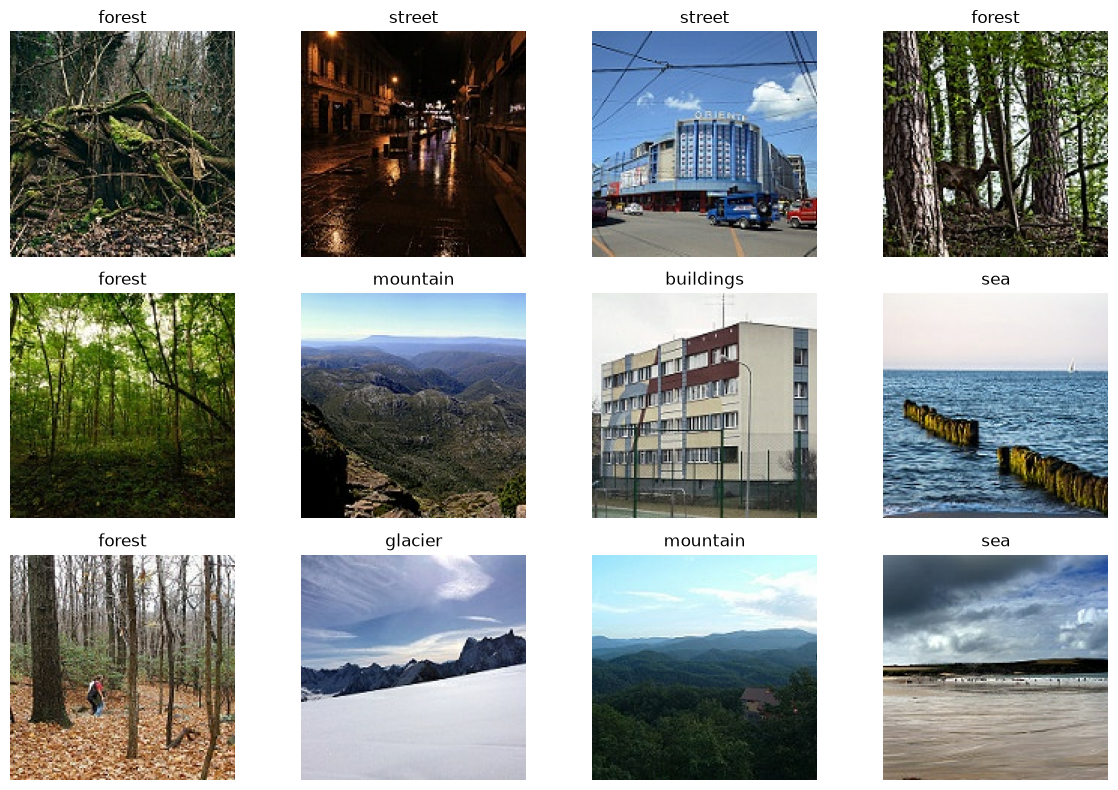

In [14]:
plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
for images, labels in train_dataset.take(1):
    print("Images:", images.shape)
    print("Labels:", labels.shape)

Images: (32, 150, 150, 3)
Labels: (32,)


In [28]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = (
    train_dataset
    .cache()
    .shuffle(1000)
    .prefetch(AUTOTUNE)
)

validation_dataset = validation_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

In [29]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(150, 150, 3)),
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(filters=16, kernel_size=(3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Conv2D(filters=32, kernel_size=(3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Conv2D(filters=64, kernel_size=(3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(6, activation='softmax')
])

In [30]:
model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy'],
)

In [31]:
class EarlyStoppingCallback(tf.keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):

        if logs.get('accuracy') >= 0.95 and logs.get('val_accuracy') < 0.80:
            self.model.stop_training = True

In [32]:
history = model.fit(
    train_dataset,
    validation_data= validation_dataset,
    epochs = 10,
    callbacks = [EarlyStoppingCallback()]
)

Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 26s 72ms/step - accuracy: 0.6459 - loss: 0.9258 - val_accuracy: 0.6989 - val_loss: 0.7803
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 24s 70ms/step - accuracy: 0.7783 - loss: 0.6020 - val_accuracy: 0.7858 - val_loss: 0.5887
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 25s 70ms/step - accuracy: 0.8351 - loss: 0.4509 - val_accuracy: 0.7826 - val_loss: 0.6361
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 25s 70ms/step - accuracy: 0.8922 - loss: 0.3012 - val_accuracy: 0.8083 - val_loss: 0.6007
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 25s 70ms/step - accuracy: 0.9319 - loss: 0.1968 - val_accuracy: 0.8047 - val_loss: 0.6781
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 25s 70ms/step - accuracy: 0.9624 - loss: 0.1098 - val_accuracy: 0.8036 - val_loss: 0.8957
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 25s 71ms/step - accuracy: 0.9715 - loss: 0.0891 - val_accuracy: 0.7919 - val_loss: 0.9116


In [33]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 18496)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │     9,470,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │         3,078 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,491,380 (108.69 MB)

 Trainable params: 9,497,126 (36.23 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 18,994,254 (72.46 MB)

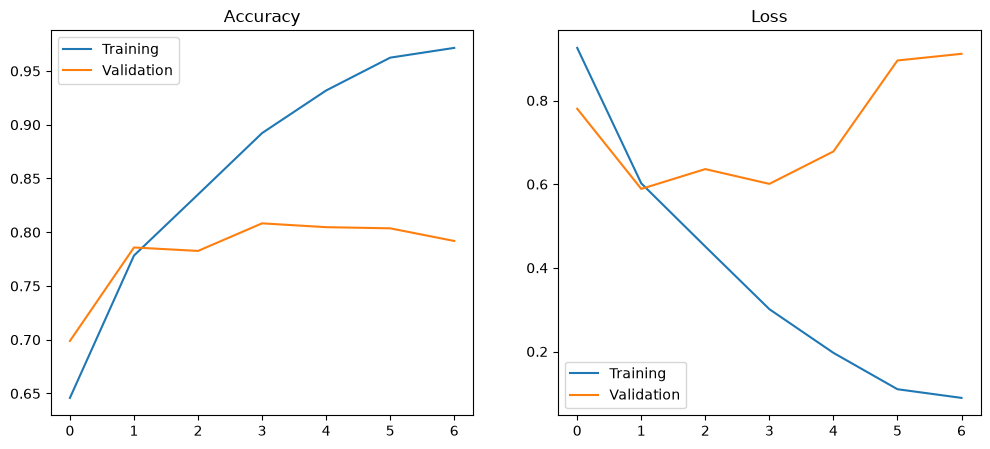

In [34]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.legend()

plt.show()

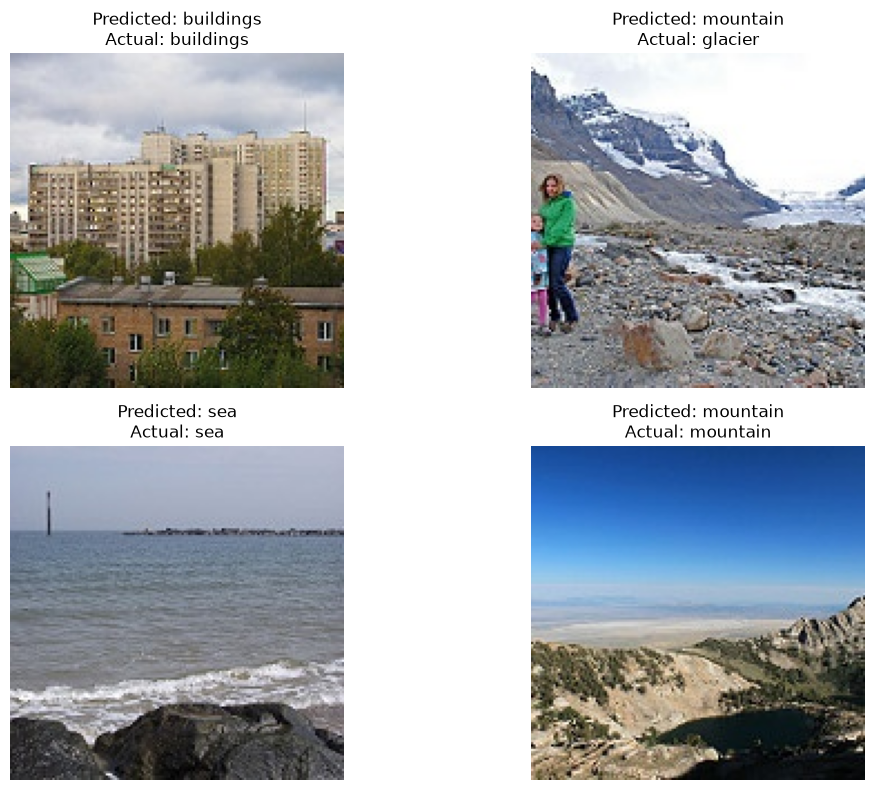

In [38]:
import random
import numpy as np
plt.figure(figsize=(12, 8))

for i in range(4):
    class_name = random.choice(class_names)
    image_path = os.path.join(test_dir, class_name, random.choice(os.listdir(os.path.join(test_dir, class_name))))

    image = tf.keras.utils.load_img(image_path, target_size=(150, 150))
    image_array = tf.keras.utils.img_to_array(image)

    prediction = model.predict(np.expand_dims(image_array, axis=0), verbose=0)
    predicted_class = class_names[np.argmax(prediction)]

    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.title(f"Predicted: {predicted_class}\nActual: {class_name}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [40]:
model.save("intel_cnn_base_model.keras")